### Check the dataset

In [1]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from urllib.parse import urlparse
from datasets import load_dataset
import re, math, random, collections

/home/arjunprasaath/miniconda3/envs/llm_jax/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
dataset_math = load_dataset("datasets/datasets/finemath-4plus/")
dataset_wiki = load_dataset("datasets/datasets/data/enwiki/")
dataset_web = load_dataset("datasets/datasets/sample/10BT/")

Generating train split: 6614655 examples [01:34, 69693.96 examples/s] 
Generating train split: 9672101 examples [01:21, 118865.56 examples/s]


In [34]:
print(len(dataset_math["train"]), len(dataset_wiki["train"]), len(dataset_web["train"]))

6699493 6614655 9672101


In [22]:
print(dataset_math["train"][0]['text'])

# What is the term”exclamation mark” in mathematics?

The answer is easy. Below are some approaches to inform as soon as an equation can be really actually a multiplication equation and also how to add and subtract using”exclamation marks”. For instance,”2x + 3″ imply”multiply two integers from about a few, making a value add up to 2 and 3″.

By way of example,”2x + 3″ are multiplication by write a paper online three. In addition, we can add the values of 2 and 3 collectively. To add the worth, we’ll use”e”that I” (or”E”). With”I” means”include the worth of one to the worth of 2″.

To add the worth , we can certainly do this similar to that:”x – y” means”multiply x by y, making a worth equal to zero”. For”x”y”, we’ll use”t” (or”TE”) for the subtraction and we’ll use”x y y” to solve the equation.

You might feel that you are not supposed to utilize”e” in addition as”I” implies”subtract” however it’s perhaps not so easy. https://www.masterpapers.com For instance, to express”2 – 3″ approa

In [26]:
print(dataset_wiki["train"][0]['text'])

# 10th Tank Corps
The 10th Tank Corps was a tank corps of the Red Army, formed twice.

## First Formation
In May–June 1938, the 7th Mechanized Corps headquarters was relocated from Novy Petergof to Luga and converted into the 10th Tank Corps when the Red Army mechanized forces transitioned from a mechanized corps structure to a tank corps structure. On 4 August 1938, the 107th Separate Air Liaison Flight was formed as part of the corps at Luga. On 27 September 1939, the corps was relocated to the Pskov area on the Estonian border, to back up threats of force against that country. On 2 October it was moved to the Latvian border to threaten Latvia as well. Both of these movements were made to force the two Baltic states into signing the Soviet–Estonian Mutual Assistance Treaty and the Soviet–Latvian Mutual Assistance Treaty, respectively, which established Soviet military bases on the territory of both countries. On 10 October, the 18th Light Tank Brigade was transferred to another unit 

In [36]:
print(dataset_web['train'][0]['text'])

The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’s refusal of Mr. Collins offer of marriage showed an independence seldom seen in heroines of the day. Her refusal of Mr. Darcy while triggered by anger showed a level of independence that left him shocked and stunned.
The freedom she exhibited in finally accepting him in direct defiance of Lady Catherine and knowing her father would disapprove was unusual even for Austen. In her last book Anne Elliot is persuaded to refuse Captain Wentworth at Lady Russel’s insistence.
Although Jane played by the rules of the day, all of her writing is infused with how she wanted life to be. She ‘screams’ her outrage at the limitations for women in Emma.
When accosted by Mrs. Elton, Jane Fairfax says,
“Excuse me, ma’am, but this is by no means my intention; I make no inquiry myself, and should be sorry to 

In [42]:
ds_3k = dataset_web['train'].select(range(3000))

In [49]:
ds_3k

Dataset({
    features: ['text', 'id', 'dump', 'url', 'file_path', 'language', 'language_score', 'token_count', 'score', 'int_score'],
    num_rows: 3000
})

In [69]:
N_DOCS = 3000
print(f"Streaming {N_DOCS} docs from FineWeb sample-10BT ...")
stream = load_dataset(
   "datasets/datasets/sample/10BT",
   split="train",
   streaming=True,
)
docs = []
for i, doc in enumerate(tqdm(stream, total=N_DOCS)):
   docs.append(doc)
   if i + 1 >= N_DOCS:
       break
      
df = pd.DataFrame(docs)
print("\nColumns:", list(df.columns))
print(df[["url", "language", "language_score", "token_count"]].head(5))
ex = docs[0]
print("\n--- Example record (fields) ---")
for k, v in ex.items():
   preview = (v[:120] + "…") if isinstance(v, str) and len(v) > 120 else v
   print(f"{k:>16}: {preview}")

Streaming 3000 docs from FineWeb sample-10BT ...


100%|█████████▉| 2999/3000 [00:00<00:00, 22368.45it/s]


Columns: ['text', 'id', 'dump', 'url', 'file_path', 'language', 'language_score', 'token_count', 'score', 'int_score']
                                                 url language  language_score  \
0      http://austenauthors.net/the-independent-jane       en        0.974320   
1  http://query.nytimes.com/gst/fullpage.html?res...       en        0.961459   
2  http://www.childline.org.uk/Explore/SexRelatio...       en        0.966757   
3  http://www.ctt.org/resource_centre/getting_sta...       en        0.910602   
4  http://www.environment.ucla.edu/water/news/art...       en        0.924981   

   token_count  
0          845  
1         1055  
2          136  
3         3479  
4         1115  

--- Example record (fields) ---
            text: The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom…
              id: <urn:uuid:0d8a309d-25c5-405d-a08a-c11239f0d717>
            dump: CC-MAIN-2013-20
             url: 

In [74]:
WORD = re.compile(r"\b\w+\b")
def gopher_quality(text):
   words = WORD.findall(text)
   n = len(words)
   if n < 50 or n > 100_000:
       return False, "word_count_out_of_range"
   mean_len = sum(len(w) for w in words) / n
   if mean_len < 3 or mean_len > 10:
       return False, "bad_mean_word_length"
   if (text.count("#") + text.count("...")) / n > 0.1:
       return False, "too_many_symbols"
   lines = text.split("\n")
   if lines and sum(l.lstrip().startswith(("•", "-", "*")) for l in lines) / len(lines) > 0.9:
       return False, "mostly_bullets"
   stops = {"the", "be", "to", "of", "and", "that", "have", "with"}
   if len(stops & {w.lower() for w in words}) < 2:
       return False, "too_few_stopwords"
   return True, "ok"
def c4_quality(text):
   lines = [l for l in text.split("\n") if l.strip()]
   if not lines:
       return False, "empty"
   low = text.lower()
   for bad in ("lorem ipsum", "javascript is disabled"):
       if bad in low:
           return False, f"boilerplate:{bad}"
   if text.count("{") > 0 and text.count("{") / max(len(lines), 1) > 0.5:
       return False, "too_many_braces"
   return True, "ok"
def fineweb_custom(text):
   lines = [l.strip() for l in text.split("\n") if l.strip()]
   if not lines:
       return False, "empty"
   dup_frac = 1 - len(set(lines)) / len(lines)
   if dup_frac > 0.3:
       return False, "duplicated_lines"
   short_frac = sum(len(l) < 30 for l in lines) / len(lines)
   if short_frac > 0.67 and len(lines) > 5:
       return False, "list_like"
   return True, "ok"
results = []
for d in docs:
   t = d["text"]
   g_ok, g_r = gopher_quality(t)
   c_ok, c_r = c4_quality(t)
   f_ok, f_r = fineweb_custom(t)
   reason = "kept" if (g_ok and c_ok and f_ok) else (g_r if not g_ok else c_r if not c_ok else f_r)
   results.append(reason)
filter_summary = pd.Series(results).value_counts()
print("\n--- Quality-filter outcomes on already-clean FineWeb data ---")
print("(Most pass: FineWeb is pre-filtered. Rejections show what the rules catch.)")
print(filter_summary)


--- Quality-filter outcomes on already-clean FineWeb data ---
(Most pass: FineWeb is pre-filtered. Rejections show what the rules catch.)
kept                       2991
mostly_bullets                8
word_count_out_of_range       1
Name: count, dtype: int64


In [75]:
from datasketch import MinHash, MinHashLSH

def shingles(text, k=5):
   toks = WORD.findall(text.lower())
   return {" ".join(toks[i:i+k]) for i in range(max(len(toks) - k + 1, 1))}

NUM_PERM = 128
THRESHOLD = 0.7

lsh = MinHashLSH(threshold=THRESHOLD, num_perm=NUM_PERM)
minhashes = {}

for idx, d in enumerate(tqdm(docs, desc="MinHashing")):
   m = MinHash(num_perm=NUM_PERM)
   for s in shingles(d["text"]):
       m.update(s.encode("utf8"))
   minhashes[idx] = m
   lsh.insert(str(idx), m)
dup_pairs = set()
for idx, m in minhashes.items():
   for cand in lsh.query(m):
       c = int(cand)
       if c != idx:
           dup_pairs.add(tuple(sorted((idx, c))))
print(f"\nFound {len(dup_pairs)} near-duplicate pairs (Jaccard ≥ {THRESHOLD}).")
if dup_pairs:
   a, b = next(iter(dup_pairs))
   j = minhashes[a].jaccard(minhashes[b])
   print(f"Example pair (estimated Jaccard ≈ {j:.2f}):")
   print("  DOC A:", docs[a]["text"][:160].replace("\n", " "), "…")
   print("  DOC B:", docs[b]["text"][:160].replace("\n", " "), "…")
else:
   print("No near-dupes in this slice — expected, since FineWeb is dedup'd per crawl.")

MinHashing:   0%|          | 0/3000 [00:00<?, ?it/s]

MinHashing: 100%|██████████| 3000/3000 [00:11<00:00, 261.87it/s]


Found 0 near-duplicate pairs (Jaccard ≥ 0.7).
No near-dupes in this slice — expected, since FineWeb is dedup'd per crawl.


In [83]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")
check = docs[:200]
recomputed = [len(enc.encode(d["text"])) for d in tqdm(check, desc="Tokenizing")]
stored = [d["token_count"] for d in check]
diffs = np.array(recomputed) - np.array(stored)
print(f"\n--- Verifying token_count field (o1) on 200 docs ---")
print(f"Mean abs diff vs stored token_count: {np.abs(diffs).mean():.2f} tokens")
print(f"Exact matches: {(diffs == 0).mean()*100:.0f}%   (small drift = tokenizer version)")
df["chars_per_token"] = df["text"].str.len() / df["token_count"].clip(lower=1)
print(f"Avg characters per token: {df['chars_per_token'].mean():.2f}")

Tokenizing: 100%|██████████| 200/200 [00:00<00:00, 6236.05it/s]


--- Verifying token_count field (o1) on 200 docs ---
Mean abs diff vs stored token_count: 23.18 tokens
Exact matches: 4%   (small drift = tokenizer version)
Avg characters per token: 4.64



--- Top 15 domains in sample ---
domain
en.wikipedia.org                 41
sciencedaily.com                 20
britannica.com                   19
wordnik.com                      11
factmonster.com                  11
infoplease.com                    9
intelihealth.com                  9
phys.org                          8
bbc.co.uk                         8
reference.com                     8
bartleby.com                      8
all-science-fair-projects.com     7
kidshealth.org                    7
abc.net.au                        7
emedicinehealth.com               7
Name: count, dtype: int64


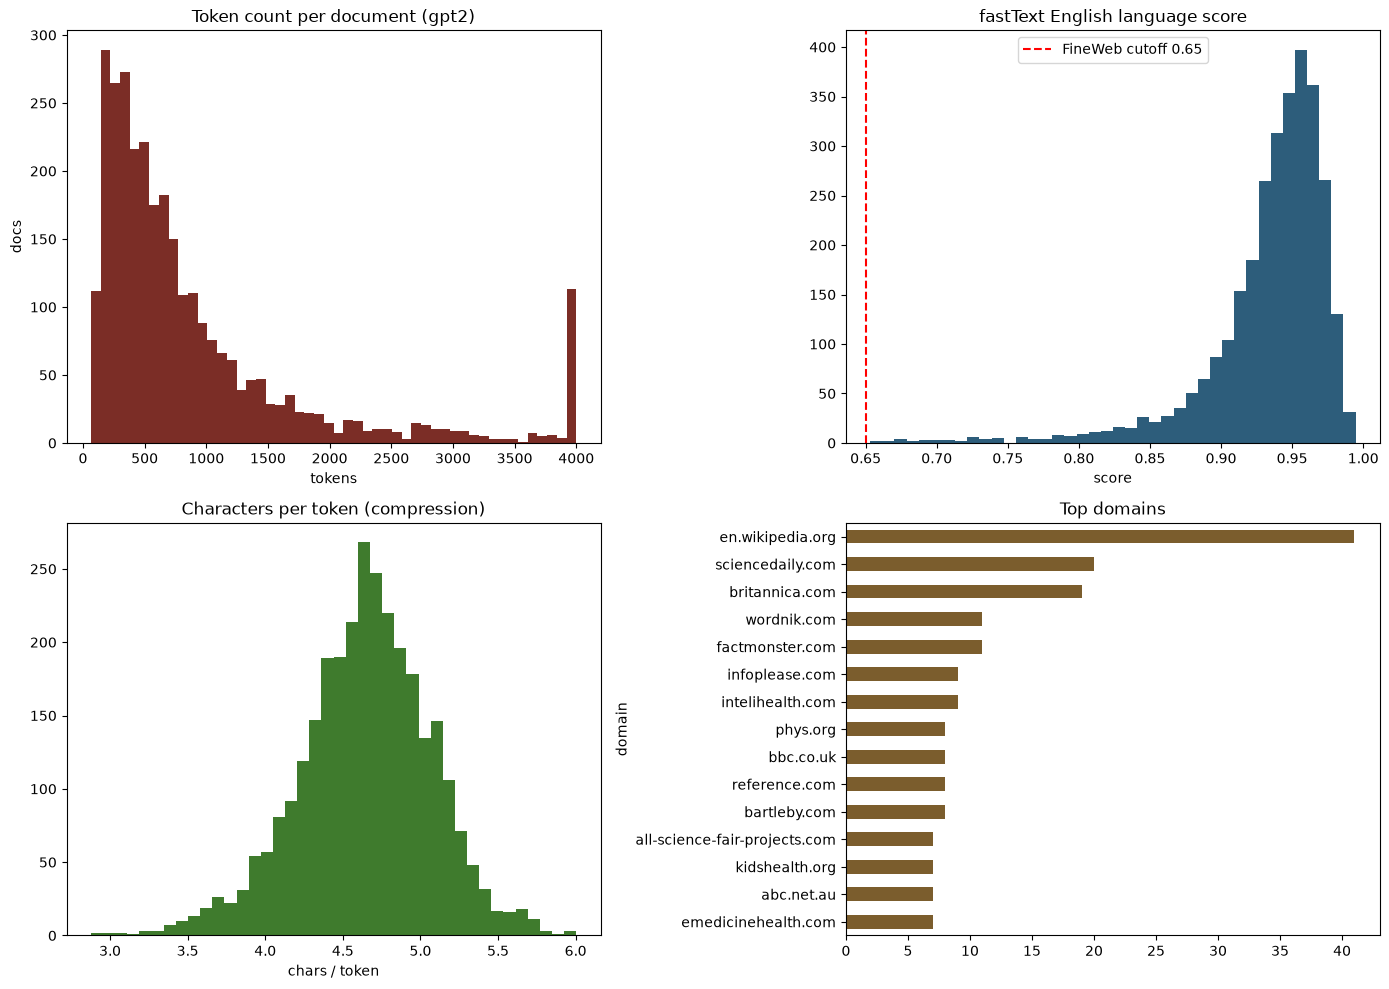


SUMMARY
Docs streamed          : 3,000
Total gpt2 tokens       : 3,151,219
Median tokens/doc       : 592
Unique domains          : 2,405
Mean language_score     : 0.934
Near-duplicate pairs    : 0
Docs flagged by filters : 9 / 3000

Next steps:
  • Swap name='sample-10BT' for a real crawl, e.g. name='CC-MAIN-2024-10'
  • Raise N_DOCS for stronger statistics
  • Use the full datatrove pipeline to reproduce FineWeb end-to-end


In [88]:
df["domain"] = df["url"].apply(lambda u: urlparse(u).netloc.replace("www.", "") if isinstance(u, str) else "?")
top_domains = df["domain"].value_counts().head(15)
print("\n--- Top 15 domains in sample ---")
print(top_domains)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(df["token_count"].clip(upper=4000), bins=50, color="#7b2d26")
axes[0, 0].set_title("Token count per document (gpt2)")
axes[0, 0].set_xlabel("tokens"); axes[0, 0].set_ylabel("docs")
axes[0, 1].hist(df["language_score"], bins=40, color="#2d5d7b")
axes[0, 1].axvline(0.65, color="red", ls="--", label="FineWeb cutoff 0.65")
axes[0, 1].set_title("fastText English language score")
axes[0, 1].set_xlabel("score"); axes[0, 1].legend()
axes[1, 0].hist(df["chars_per_token"].clip(upper=8), bins=40, color="#3f7b2d")
axes[1, 0].set_title("Characters per token (compression)")
axes[1, 0].set_xlabel("chars / token")
top_domains.iloc[::-1].plot(kind="barh", ax=axes[1, 1], color="#7b5d2d")
axes[1, 1].set_title("Top domains")
plt.tight_layout()
plt.show()
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"Docs streamed          : {len(df):,}")
print(f"Total gpt2 tokens       : {df['token_count'].sum():,}")
print(f"Median tokens/doc       : {int(df['token_count'].median())}")
print(f"Unique domains          : {df['domain'].nunique():,}")
print(f"Mean language_score     : {df['language_score'].mean():.3f}")
print(f"Near-duplicate pairs    : {len(dup_pairs)}")
print(f"Docs flagged by filters : {(pd.Series(results) != 'kept').sum()} / {len(results)}")
print("\nNext steps:")
print("  • Swap name='sample-10BT' for a real crawl, e.g. name='CC-MAIN-2024-10'")
print("  • Raise N_DOCS for stronger statistics")
print("  • Use the full datatrove pipeline to reproduce FineWeb end-to-end")

### Datatrove

In [3]:
from datatrove.pipeline.readers import ParquetReader
from datatrove.pipeline.writers import ParquetWriter
from datatrove.executor import LocalPipelineExecutor

from datatrove.pipeline.filters import (
    GopherQualityFilter,
    GopherRepetitionFilter,
)
from datatrove.pipeline.dedup.exact_dedup import (
    ExactDedupSignature,
    ExactFindDedups,
    ExactDedupFilter,
)

from datatrove.pipeline.dedup.minhash import(
    MinhashConfig,
    MinhashDedupSignature,
    MinhashDedupBuckets,
    MinhashDedupCluster,
    MinhashDedupFilter,
)

from datatrove.pipeline.dedup.sentence_dedup import(
    SentDedupConfig,
    SentenceDedupSignature,
    SentenceFindDedups,
    SentenceDedupFilter,
)

from datatrove.pipeline.tokens.counter import TokensCounter
from datatrove.pipeline.stats.doc_stats import DocStats
from datatrove.pipeline.stats.perplexity_stats import CCNetPerplexityStats

INPUT_DATA = "datasets/datasets/sample/10BT/"
BASE_WORKINGDIR = "datasets/pipeline_workspace"

TASKS = 1
WORKERS = 1

In [4]:
stage1_out = f"{BASE_WORKINGDIR}/stage1_filtered"
stage1_executor = LocalPipelineExecutor(
    pipeline = [
        ParquetReader(data_folder = INPUT_DATA),
        GopherQualityFilter(),
        GopherRepetitionFilter(),
        TokensCounter(),
        CCNetPerplexityStats(output_folder = stage1_out, model_dataset= "wikipedia", language= "en"),
        ParquetWriter(output_folder = stage1_out)
    ],
    tasks = TASKS,
    workers = WORKERS,
)

In [5]:
stage1_executor.run()

2026-10-17 13:39:02.985 | INFO     | datatrove.utils.logging:add_task_logger:76 - Launching pipeline for rank=0
2026-10-17 13:39:02.987 | INFO     | datatrove.utils.logging:log_pipeline:108 - 
--- 🛠️ PIPELINE 🛠
📖 - READER: 📒 Parquet
🔻 - FILTER: 🥇 Gopher Quality
🔻 - FILTER: 👯 Gopher Repetition
🔢 - TOKENIZER: 📊 Counter
📊 - STATS: 🤯 CCNet perplexity stats
💽 - WRITER: 📒 Parquet
2026-10-17 13:39:02.989 | INFO     | datatrove.pipeline.readers.base:read_files_shard:215 - Reading input file 000_00000.parquet, 1/14


KeyboardInterrupt: 